<a href="https://colab.research.google.com/github/Miller12567/2026_Geodesy_TSC/blob/main/5201_Lab_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Introduction to Seismology

Earth 5201

Homework 3

Due Monday October 26, 2026

1) Last year there was an earthquake in Oak Hill, OH
(https://earthquake.usgs.gov/earthquakes/eventpage/se60597816/executive).

We will assume that the depth of the earthquake is the published depth of 25.9 km.

The following nearby stations have nice P wave arrivals: N4.Q51A, N4.Q52A, OH.CHWO, OH.CPOH, OH.DSFO, and OH.SSF2.

A) Retrieve the vertical component waveforms for each of these stations and determine the P wave by manually picking it (for this, you can zoom into the time of the P wave arrival and get it roughly to the nearest tenth of a second).





In [19]:
%pip install obspy -q

In [20]:
import numpy as np
import matplotlib.pylab as plt
import obspy as op
from obspy.clients.fdsn import Client
from obspy import UTCDateTime
from obspy.taup import TauPyModel
from obspy.geodetics.base import gps2dist_azimuth, kilometer2degrees
from obspy.geodetics import locations2degrees
import numpy as np
import matplotlib.pyplot as plt

2025-02-03T21:04:56.800000Z 2025-02-03T21:05:56.800000Z


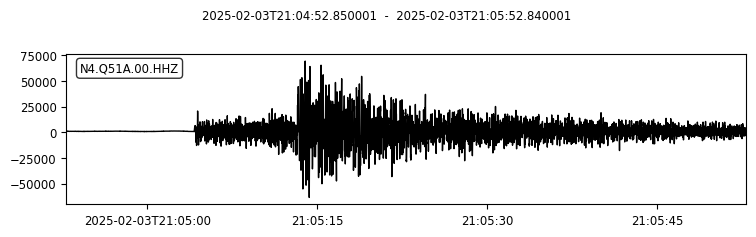

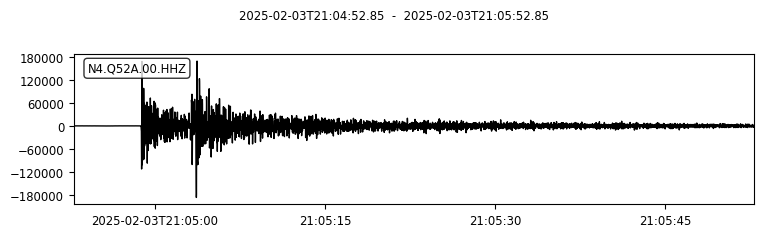

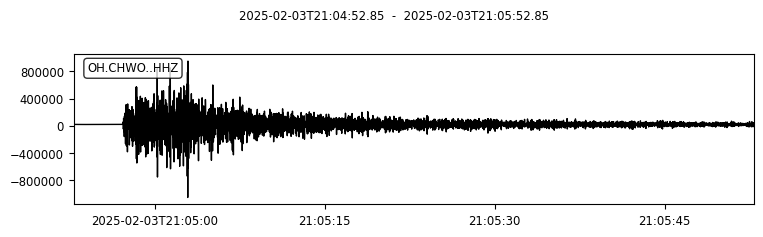

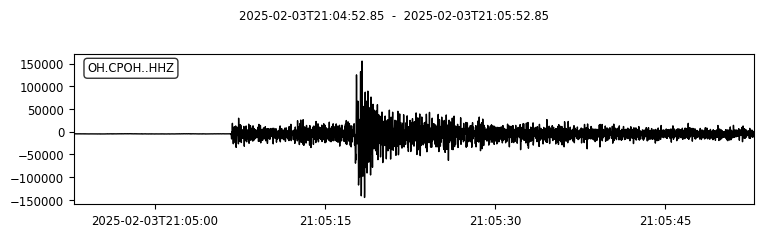

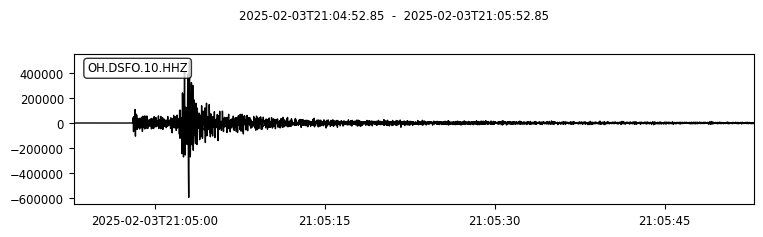

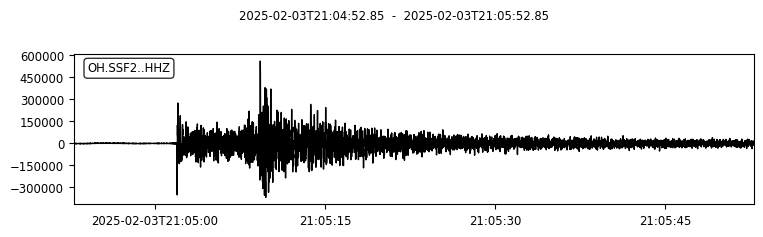

In [21]:
ES = Client("EARTHSCOPE")
USGS = Client("USGS")
true_0 = UTCDateTime("2025,02,03,21,04,52.850")
t0 = "2025, 02, 03, 21, 04, 56.8"
t60 = "2025, 02, 03, 21, 05, 56.8"
T0 = UTCDateTime(t0)
T60 = UTCDateTime(t60)
print(T0,T60)

Q51A=ES.get_waveforms(
    network="N4",
    station="Q51A",
    location="00",
    channel="HHZ",
    starttime=true_0,
    endtime=true_0 + 60,
)
Q51A.plot()
Q51A_P = true_0 + 11.3

Q52A = ES.get_waveforms(
    network="N4",
    station="Q52A",
    location="00",
    channel="HHZ",
    starttime=true_0,
    endtime=true_0 + 60,
)
Q52A.plot()
Q52A_P = true_0 + 5.95

CHWO = ES.get_waveforms(
    network="OH",
    station="CHWO",
    location="",
    channel="HHZ",
    starttime=true_0,
    endtime=true_0+60,
)
CHWO.plot()
CHWO_P = true_0 + 4.4

CPOH = ES.get_waveforms(
    network="OH",
    station="CPOH",
    location="",
    channel="HHZ",
    starttime=true_0 + 0,
    endtime=true_0 + 60,
)
CPOH.plot()
CPOH_P = true_0 + 13.9

DSFO = ES.get_waveforms(
    network="OH",
    station="DSFO",
    location="10",
    channel="HHZ",
    starttime=true_0,
    endtime=true_0 + 60,
)
DSFO.plot()
DSFO_P = true_0 + 5.3

SSF2 = ES.get_waveforms(
    network="OH",
    station="SSF2",
    location="",
    channel="HHZ",
    starttime=true_0 + 0,
    endtime=true_0 + 60,
)
SSF2.plot()

# I did eyeball all the P-wave arrival times by zooming in by chaning the times but i left them as a whole 60s window to no spam this with a bunch of plots.
SSF2_P = true_0 + 9.1
#i have no idea why it makes two, getting rid of the line above removes both so this problem is beyond my pay grade.


B) Given the published location of the earthquake of 38.920N and 82.581 W, find a single P-wave velocity that best fits the data.

To compute hypocentral distances, the function geopy.distance.distance works well to get epicentral distance, and then you can do sqrt(epidist^2+depth^2)=hypodist. Usage for geopy.distance.distance is:

coord1 = (lat1,lon1)

coord1 = (lat2,lon2)

epidist = geopy.distance.distance(coord1,coord2).km

In [22]:
import geopy
from geopy.distance import distance
olat = 38.920
olon = -82.581
depth = 25.9
latlon = (olat,olon) # origin

station_coordinateslat=[
39.026,
38.9622,
38.93602,
38.8401,
38.690952,
38.6886]

station_coordinateslon=[
-83.3456,
-82.2669,
-82.526105,
-83.5776,
-82.616898,
-83.1276]

arrival_times=[
Q51A_P - true_0,
Q52A_P - true_0,
CHWO_P - true_0,
CPOH_P - true_0,
DSFO_P - true_0,
SSF2_P - true_0]

hypo_distances = []
times = []
# Calculate distances and gather data

for i in range(0, 6):

  new_latlon = (station_coordinateslat[i],station_coordinateslon[i])

  epi_dist = distance(latlon, new_latlon).km

  hypo_dist = np.sqrt(epi_dist**2 + depth**2)

  hypo_distances.append(hypo_dist)

  times.append(arrival_times[i])

slope, intercept = np.polyfit(hypo_distances, times, 1)

v_p = 1.0 / slope

print(f"Best-fit P-wave velocity (Vp): {v_p:.2f} km/s")

Best-fit P-wave velocity (Vp): 6.57 km/s


C) Using the AK135 velocity model in the obspy.taup package, determine the optimal L2-norm location for the earthquake and origin time difference, plotting the misfit space as I did in lecture15_eq_location Jupyter notebook. For this, create a grid around the published epicenter, +- 0.5 degrees in both latitude and longitude with 0.01 degree grid spacing.

You will want to use the little ‘p’ theoretical travel time in obspy.taup. Since obspy.taup expects distance in degrees, use the obspy.geodetics.base.gps2dist_azimuth function to get your distances between stations and grid points.





[11.97447341  6.3534964   4.43847943 14.95002897  6.1130956   9.98757121]
[11.3, 5.95, 4.4, 13.9, 5.3, 9.1]
[ 38.876 -82.559]
Grid search best-fit location: [ 38.876 -82.559]
True location:                 [ 38.92  -82.581]
Error: 0.049 degrees


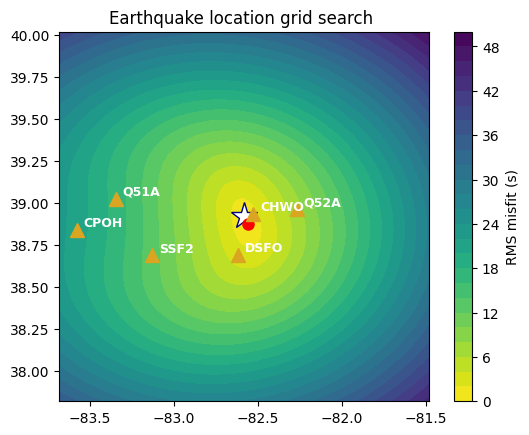

In [23]:
model=TauPyModel(model='ak135')
m1 = np.array([true_0, 38.920,  82.581, 25.9])
origin = np.array([olat, olon]) # lon lat

stations = np.array([[39.026,-83.3456],[38.9622,-82.2669],[38.93602,-82.526105],[38.8401,-83.5776],[38.690952,-82.616898],[38.6886,-83.1276]])
station_names = ["Q51A", "Q52A", "CHWO", "CPOH", "DSFO", "SSF2"]

# observations n = 6 = stations
ptt = np.zeros(6)
for i in range(len(stations)):
  dd, ee, ff = op.geodetics.base.gps2dist_azimuth(origin[0], origin[1], stations[i, 0], stations[i, 1])
  ddkm = dd / 1000 # convert to km
  dd2 = op.geodetics.kilometer2degrees(ddkm)
  F = model.get_travel_times(
    source_depth_in_km=25.9,  #depth
    distance_in_degree=dd2,  # dd2 degrees away
    phase_list=["p"], # onlt getting p waves?
  )
  ptt[i] = F[0].time

print(ptt)
print(times) # to compare my times vs the loop

yg = np.linspace(olon - 1.1, olon + 1.1, 101) # for final graph
xg = np.linspace(olat - 1.1, olat + 1.1, 101)

XX, YY = np.meshgrid(yg, xg)

misfit = np.zeros_like(XX)

lat2km = 111.19
avg_lat_rad = np.radians(olat)
lon2km = 111.19 * np.cos(avg_lat_rad)

for k in range(len(stations)):
  dy_km = (YY - stations[k, 0]) * lat2km
  dx_km = (XX - stations[k, 1]) * lon2km
  dist_km = np.sqrt(dx_km**2 + dy_km**2)

  hypo_dist= np.sqrt(dist_km**2 + depth**2)
  pred = hypo_dist / v_p
  misfit += (arrival_times[k] - pred) ** 2

best_idx = np.unravel_index(np.argmin(misfit), misfit.shape)
best_loc_grid = np.array([YY[best_idx], XX[best_idx]])
print(best_loc_grid)
print(f"Grid search best-fit location: {best_loc_grid}")
print(f"True location:                 {origin}")
print(f"Error: {np.linalg.norm(best_loc_grid - origin):.3f} degrees")

plt.contourf(XX, YY, np.sqrt(misfit), levels=25, cmap="viridis_r")
plt.colorbar(label="RMS misfit (s)")
plt.plot(olon, olat, "*", color="white", markersize=20, markeredgecolor="navy")
plt.plot(best_loc_grid[1], best_loc_grid[0], "o", color="red", markersize=8)
plt.plot(stations[:, 1], stations[:, 0], "^", color="goldenrod", markersize=10)
for i, name in enumerate(station_names):
  # Adjusting text offset so that labels don't overlap the station icons
  plt.text(stations[i, 1] + 0.04, stations[i, 0] + 0.02, name, color="white", fontsize=9, fontweight="bold")



plt.gca().set_aspect("equal")
plt.title("Earthquake location grid search ")
plt.show()

D) For earthquake early warning, you need a few seconds of P wave data for 4 stations to determine an earthquake magnitude and origin time. For this earthquake and the 4 closest sites that you analyzed, assuming you need 3 seconds of P wave data, how many seconds of warning would we receive in Mendenhall Laboratory using taup theoretical ‘s’ travel times?

Hint: the warning time will be the theoretical S-wave travel time minus the time at
which the magnitude is computed, in this case 3 seconds after the P wave arrivals at the 4th station.

In [93]:
MH = np.array([39.998396602023966, -83.01115776756465])
#4 closeest are CHWO,Q52A, DSFO, SSF2
#SSF2 is the farthest of the 4


dd2, ee2, ff2 = op.geodetics.base.gps2dist_azimuth(origin[0], origin[1], MH[0], MH[1])
ddkm2 = dd2 / 1000 # convert to km
dd3 = op.geodetics.kilometer2degrees(ddkm2)
F3 = model.get_travel_times(
  source_depth_in_km=25.9,  #depth
  distance_in_degree=dd3,  # dd2 degrees away
  phase_list=["s"], # onlt getting p waves?
)
# i am going to assume warning to Mendenhall information travel is instant
t_warning = SSF2_P + 3 # time warning gets to Mendenhall from station.
S_MH = true_0 + F3[0].time # time s wave gets to Mendenhall
warning_diff = S_MH -  t_warning
print("You will have", warning_diff, "seconds of warning before the s wave arriaval")




2025-02-03T21:05:04.950000Z
2025-02-03T21:05:27.893304Z
You will have 22.943304 seconds of warning before the s wave arriaval
